# Sigue un mineral de cobre por trituración y molienda

Nivel: 1. Requisitos previos: Ninguno; comienza aquí. Tiempo de lectura: 18 minutos.

## Objetivos

Partiendo de un mineral OreFlow declarado y su punto operativo nominal, sigue el tamaño de alimentación a través del circuito de conminución. Distingue un registro simulado de planta de una medición y reconoce las magnitudes que calcula el motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores del proyecto OreFlow. Fuente: escenario versionado y de autoría propia de pórfido cuprífero blando (licencia MIT del proyecto), `data/derived/cases/copper_porphyry_soft.json`; es un escenario de modelo, no un ensayo de mina ni una medición de planta. Los resúmenes de partículas provienen de casos construidos públicos de HZDR; consulta `data/derived/source/hzdr_particle_benchmark.json` y el dossier de procedencia HZDR. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El motor representa el tamaño en una malla logarítmica fija. La trituración transforma la distribución mediante el modelo de clasificación Whiten. La molienda aplica una función de selección específica por energía y una matriz de fractura; el clasificador envía cada clase de tamaño al rebose o al reciclaje. En estado estacionario, la alimentación fresca coincide con los productos finales dentro de la tolerancia del balance unitario. Aquí llamamos a `simulate` del pipeline OreFlow; no reimplementamos ecuaciones de conminución.

Importa el catálogo de casos OreFlow y el simulador del pipeline del repositorio. El punto nominal es el estado operativo documentado del caso; el solver devuelve el mismo resultado estructurado que usa el proceso de bake.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
result = simulate(case.ore, case.plant, case.nominal)
print('familia:', case.plant.family)
print('caudal:', case.nominal.throughput_tph, 't/h')
print('F80 de alimentación:', round(result.metrics['crusher_feed_f80_um'], 1), 'um')
print('P80 de producto:', round(result.grinding.p80_um, 1), 'um')
print('energía de molienda:', round(result.grinding.specific_energy_kwh_t, 2), 'kWh/t')

familia: rougher
caudal: 720.0 t/h
F80 de alimentación: 60094.9 um
P80 de producto: 150.0 um
energía de molienda: 8.97 kWh/t


Inspecciona las distribuciones acumuladas de pasante en los límites identificados del circuito. P80 es un percentil de una distribución; no se infiere de una partícula representativa.

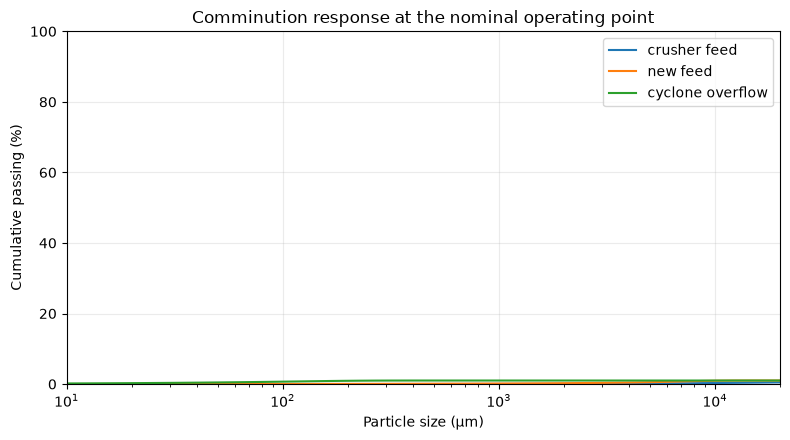

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Paso ejecutable del método OreFlow explicado en la celda anterior.
size = np.asarray(result.curves['size_um'])
psd = result.curves['psd']
fig, ax = plt.subplots(figsize=(8, 4.5))
for stream in ('crusher_feed', 'new_feed', 'cyclone_overflow'):
    ax.plot(size, psd[stream], label=stream.replace('_', ' '))
ax.set_xscale('log'); ax.set_xlim(10, 20_000); ax.set_ylim(0, 100)
ax.set(xlabel='Particle size (µm)', ylabel='Cumulative passing (%)', title='Comminution response at the nominal operating point')
ax.grid(True, alpha=.25); ax.legend()
fig.tight_layout()

Lee las métricas calculadas por etapa y el residuo máximo del balance. Un error de cierre pequeño verifica conservación numérica en esta corrida; no valida el modelo frente a una planta.

In [4]:
from IPython.display import display
import pandas as pd

# Paso ejecutable del método OreFlow explicado en la celda anterior.
metrics = result.metrics
rows = [('Crusher feed F80', metrics['crusher_feed_f80_um'], 'µm'),
        ('Crusher product P80', metrics['crusher_p80_um'], 'µm'),
        ('Circuit product P80', metrics['p80_um'], 'µm'),
        ('Specific grinding energy', metrics['specific_energy_grinding_kwh_t'], 'kWh/t'),
        ('Maximum relative balance error', result.balance['max_relative_error'], 'fraction')]
display(pd.DataFrame(rows, columns=['Quantity', 'Value', 'Unit']))

,Quantity,Value,Unit
0,Crusher feed F80,6.009494e+04,µm
1,Crusher product P80,8.417932e+03,µm
2,Circuit product P80,1.500000e+02,µm
3,Specific grinding energy,8.967354e+00,kWh/t
4,Maximum relative balance error,1.525693e-13,fraction


## Resultados

La curva PSD muestra la respuesta de tamaño del modelo en tres flujos identificados; no muestra trayectorias de partículas individuales. El residuo del balance prueba conservación dentro de este cálculo estacionario de autoría propia. Ni este caso ni sus parámetros están calibrados con una planta.

## Resumen

Ejecutaste el mismo solver de circuito que usa OreFlow, seguiste una distribución de tamaños y leíste su verificación de conservación. Distingue el cierre del modelo (consistencia interna) de la validación frente a datos medidos de planta.

## Referencias

- https://doi.org/10.1016/0301-7516(80)90034-4
- https://github.com/fsantibanezleal/CAOS_OreFlow/tree/develop/data/derived
- https://doi.org/10.1016/0301-7516(80)90034-4